In [ ]:
#  Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

DATASET_ROOT = '/content/drive/MyDrive/birds/Image_Dataset/'

Mounted at /content/drive


In [ ]:
!pip install snntorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import snntorch as snn
from snntorch import surrogate
import os


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.6/125.6 kB 3.7 MB/s eta 0:00:00


In [ ]:

# Resize ภาพเป็น 96x96 เพื่อลดเวลาเทรน
transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
])

class FilteredImageFolder(datasets.ImageFolder):
    def __init__(self, root, exclude_dirs=None, **kwargs):
        super().__init__(root, **kwargs)
        exclude_dirs = exclude_dirs or []
        exclude_dirs = [os.path.join(root, d) for d in exclude_dirs]

        # กรองโฟลเดอร์ที่ไม่ต้องการ
        self.samples = [
            (path, target) for path, target in self.samples
            if not any(path.startswith(ex) for ex in exclude_dirs)
        ]
        self.targets = [s[1] for s in self.samples]

dataset = FilteredImageFolder(
    root='/content/drive/MyDrive/birds/Image_Dataset/',
    exclude_dirs=['TrainSet'],
    transform=transform
)

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print('Classes:', dataset.classes)
print(f'Train: {len(train_dataset)} | Test: {len(test_dataset)}')


Classes: ['Common-Kingfisher', 'Common-Myna', 'House-Crow', 'Indian-Peacock', 'Indian-Pitta', 'Ruddy-Shelduck', 'Sarus-Crane', 'TrainSet']
Train: 6720 | Test: 1680


torch.Size([3, 96, 96])
torch.Size([3, 96, 96])
torch.Size([3, 96, 96])
torch.Size([3, 96, 96])
torch.Size([3, 96, 96])


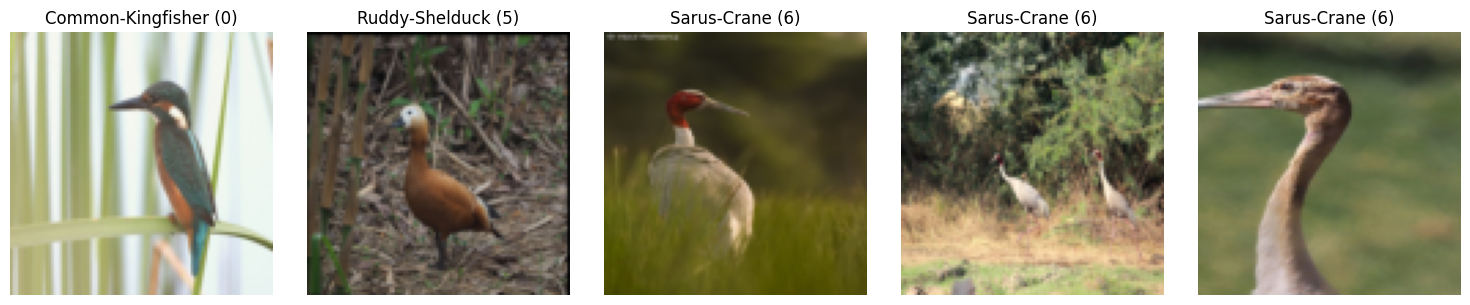

In [ ]:
import random
import matplotlib.pyplot as plt

def show_random_samples(dataset, class_names, num_samples=5):
    indices = random.sample(range(len(dataset)), num_samples)
    plt.figure(figsize=(15, 3))

    for i, idx in enumerate(indices):
        image, label = dataset[idx]
        print(image.size())

        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0).numpy()

        plt.subplot(1, num_samples, i+1)
        plt.imshow(image)
        plt.title(f"{class_names[label]} ({label})")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

class_names = dataset.classes
show_random_samples(dataset, class_names, num_samples=5)

In [ ]:

class SNN(nn.Module):
    def __init__(self, beta=0.9, num_steps=5, num_classes=7):
        super().__init__()

        self.num_steps = num_steps
        spike_grad = surrogate.fast_sigmoid(slope=25)

        # Conv Block 1: 96 -> 48
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.lif1 = snn.Leaky(beta=beta, spike_grad=spike_grad)

        # Conv Block 2: 48 -> 24
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.lif2 = snn.Leaky(beta=beta, spike_grad=spike_grad)

        # Conv Block 3: 24 -> 12
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.lif3 = snn.Leaky(beta=beta, spike_grad=spike_grad)

        self.pool = nn.MaxPool2d(2)

        # Global Average Pooling (ลดพารามิเตอร์ FC)
        self.gap = nn.AdaptiveAvgPool2d(1)

        # Fully Connected
        self.fc = nn.Linear(128, num_classes)
        self.lif_fc = snn.Leaky(beta=beta, spike_grad=spike_grad)

    def forward(self, x):
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        mem3 = self.lif3.init_leaky()
        mem_fc = self.lif_fc.init_leaky()

        spk_out = []

        # Temporal simulation
        for _ in range(self.num_steps):
            cur1 = self.pool(self.conv1(x))
            spk1, mem1 = self.lif1(cur1, mem1)

            cur2 = self.pool(self.conv2(spk1))
            spk2, mem2 = self.lif2(cur2, mem2)

            cur3 = self.pool(self.conv3(spk2))
            spk3, mem3 = self.lif3(cur3, mem3)

            gap = self.gap(spk3).squeeze(-1).squeeze(-1)
            cur_fc = self.fc(gap)
            spk_fc, mem_fc = self.lif_fc(cur_fc, mem_fc)

            spk_out.append(spk_fc)

        return torch.stack(spk_out)


In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = SNN(num_classes=len(dataset.classes)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
def train_epoch(model, loader, epoch, log_interval=10):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch_idx, (x, y) in enumerate(loader):
        x, y = x.to(device), y.to(device)

        spk_out = model(x)
        spk_mean = spk_out.mean(dim=0)

        loss = criterion(spk_mean, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # ===== Accuracy =====
        preds = spk_mean.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

        acc = 100 * correct / total   # ← ตัวนี้แหละที่หายไป

        if batch_idx % log_interval == 0:
            print(
                f"Epoch [{epoch}] "
                f"Batch [{batch_idx}/{len(loader)}] "
                f"Loss: {loss.item():.4f} "
                f"Acc: {acc:.2f}%"
            )

    return total_loss / len(loader)


In [ ]:
num_epochs = 10

def evaluate(model, loader):
    model.eval() # Set the model to evaluation mode
    correct = 0
    total = 0
    with torch.no_grad(): # Disable gradient calculations
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            spk_out = model(x)
            spk_mean = spk_out.mean(dim=0)
            preds = spk_mean.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

for epoch in range(1, num_epochs + 1):
    train_loss = train_epoch(
        model,
        train_loader,
        epoch=epoch,        # ⭐ สำคัญ
        log_interval=10
    )

    test_acc = evaluate(model, test_loader)

    print(
        f"Epoch [{epoch}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Acc: {test_acc*100:.2f}%"
    )

Epoch [1] Batch [0/210] Loss: 2.0794 Acc: 9.38%
Epoch [1] Batch [10/210] Loss: 2.0794 Acc: 14.20%
Epoch [1] Batch [20/210] Loss: 2.0794 Acc: 14.14%
Epoch [1] Batch [30/210] Loss: 2.0794 Acc: 15.12%
Epoch [1] Batch [40/210] Loss: 2.0794 Acc: 14.86%
Epoch [1] Batch [50/210] Loss: 2.0794 Acc: 14.03%
Epoch [1] Batch [60/210] Loss: 2.0794 Acc: 14.04%
Epoch [1] Batch [70/210] Loss: 2.0735 Acc: 13.91%
Epoch [1] Batch [80/210] Loss: 2.0687 Acc: 14.04%
Epoch [1] Batch [90/210] Loss: 2.0574 Acc: 14.29%
Epoch [1] Batch [100/210] Loss: 2.1239 Acc: 14.33%
Epoch [1] Batch [110/210] Loss: 2.0860 Acc: 14.50%
Epoch [1] Batch [120/210] Loss: 2.0716 Acc: 14.93%
Epoch [1] Batch [130/210] Loss: 2.0599 Acc: 15.34%
Epoch [1] Batch [140/210] Loss: 2.0753 Acc: 15.54%
Epoch [1] Batch [150/210] Loss: 2.0503 Acc: 15.46%
Epoch [1] Batch [160/210] Loss: 2.0591 Acc: 15.39%
Epoch [1] Batch [170/210] Loss: 2.0380 Acc: 15.22%
Epoch [1] Batch [180/210] Loss: 2.0139 Acc: 15.26%
Epoch [1] Batch [190/210] Loss: 2.0291 Acc: